In [20]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511058/notebook

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511058/notebook


In [21]:
import os
import sys
import pandas as pd
import time
# Masukkan folder src ke jalur pencarian Python
sys.path.insert(0, os.path.abspath("../src"))

# Cek apakah file utils_cv.py ditemukan
print(os.listdir("../src"))

from utils_cv import baca, tampil
from utils_cv import kontras_bercak

['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__', 'praproses.py']


##**Kode 4.1 Verifikasi konvolusi manual**

In [22]:
import time

def konvolusi(img, k):  # fungsi dari slide P4
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(
                pad[y:y+kh, x:x+kw] * k
            )

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img, k):  # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))


nama = "teh_041.png"

bersih = cv2.cvtColor(
    baca(f"../data/sintetis/bersih/{nama}"),
    cv2.COLOR_BGR2GRAY
)

md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)


for nm, k in {
    "rerata": np.ones((3, 3)) / 9,
    "asimetris": np.array(
        [[1, 0, -1],
         [2, 0, -2],
         [1, 0, -1]], float
    )
}.items():

    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(
        bersih, -1, k,
        borderType=cv2.BORDER_REPLICATE
    )
    t_cv = time.perf_counter() - t0

    beda = np.abs(a.astype(int) - b.astype(int)).max()

    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

    print(
        f"{nm}: selisih manual vs filter2D={beda}, "
        f"sejati vs filter2D={beda2}, "
        f"waktu manual={t_manual:.3f} s, "
        f"filter2D={t_cv:.5f} s"
    )

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.975 s, filter2D=0.00060 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=2.038 s, filter2D=0.00037 s


##**Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB**

In [23]:
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(
        img.astype(float) + rng.normal(0, sd, img.shape),
        0, 255
    ).astype(np.uint8)


def derau_sp(img, p):  # p = proporsi piksel rusak
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out


def ukur_waktu(f, x, ulang=20):  # rerata dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        t.append(time.perf_counter() - t0)

    return 1000 * np.mean(t)


# Membuat lima jenis derau
derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}


# Enam jenis penapis
penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}


# Pengujian semua kombinasi
baris = []

for dn, d in derau.items():

    # Kondisi tanpa penapis
    baris.append([
        dn,
        "tanpa",
        cv2.PSNR(bersih, d),
        0.0,
        kontras_bercak(d, md, mb)
    ])

    # Kondisi menggunakan enam penapis
    for pn, f in penapis.items():
        out = f(d)

        baris.append([
            dn,
            pn,
            cv2.PSNR(bersih, out),
            ukur_waktu(f, d),
            kontras_bercak(out, md, mb)
        ])


tabel = pd.DataFrame(
    baris,
    columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]
).round(2)

print(tabel)

tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.35
1   gauss_10  rerata_3    36.79      0.12  5.36
2   gauss_10  rerata_5    37.30      0.17  5.49
3   gauss_10   gauss_5    37.57      0.26  5.51
4   gauss_10  median_3    35.46      0.09  5.32
5   gauss_10  median_5    38.19      0.78  6.13
6   gauss_10  median_9    38.07     14.22  6.86
7   gauss_20     tanpa    22.12      0.00  1.93
8   gauss_20  rerata_3    31.41      0.12  4.26
9   gauss_20  rerata_5    34.34      0.14  4.97
10  gauss_20   gauss_5    32.54      0.25  4.55
11  gauss_20  median_3    29.71      0.10  3.87
12  gauss_20  median_5    33.35      0.73  4.96
13  gauss_20  median_9    35.19     14.18  5.62
14  gauss_40     tanpa    16.55      0.00  1.00
15  gauss_40  rerata_3    25.96      0.12  2.76
16  gauss_40  rerata_5    29.77      0.15  3.86
17  gauss_40   gauss_5    27.16      0.25  3.09
18  gauss_40  median_3    23.83      0.09  2.29
19  gauss_40  median_5    27.80      0.7

##**Grafik Seluruh Hasil**

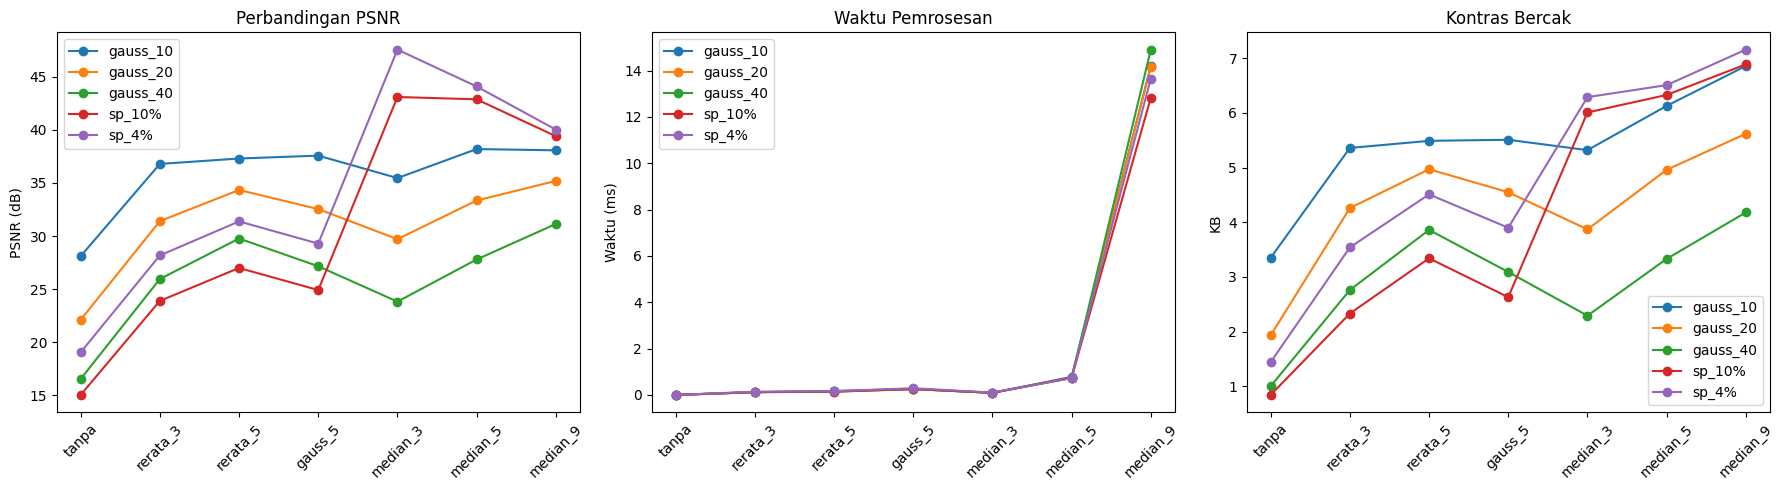

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Grafik PSNR
for nama_derau, grup in tabel.groupby("derau"):
    ax[0].plot(
        grup["penapis"],
        grup["PSNR_dB"],
        marker="o",
        label=nama_derau
    )

ax[0].set_title("Perbandingan PSNR")
ax[0].set_ylabel("PSNR (dB)")
ax[0].tick_params(axis="x", rotation=45)
ax[0].legend()


# Grafik waktu
for nama_derau, grup in tabel.groupby("derau"):
    ax[1].plot(
        grup["penapis"],
        grup["waktu_ms"],
        marker="o",
        label=nama_derau
    )

ax[1].set_title("Waktu Pemrosesan")
ax[1].set_ylabel("Waktu (ms)")
ax[1].tick_params(axis="x", rotation=45)
ax[1].legend()


# Grafik KB
for nama_derau, grup in tabel.groupby("derau"):
    ax[2].plot(
        grup["penapis"],
        grup["KB"],
        marker="o",
        label=nama_derau
    )

ax[2].set_title("Kontras Bercak")
ax[2].set_ylabel("KB")
ax[2].tick_params(axis="x", rotation=45)
ax[2].legend()

plt.tight_layout()
plt.savefig("../hasil/b4_grafik_penapis.png", dpi=150)
plt.show()

##**Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil**

In [25]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|"""

    k = kanal.astype(float)

    sehat = (mask_daun > 0) & (mask_bercak == 0)

    return abs(
        k[mask_bercak > 0].mean() - k[sehat].mean()
    )


label = pd.read_csv("../data/sintetis/label.csv")

baris = []

for nm in label[label.kelas == "ringan"].nama_file:

    g = cv2.cvtColor(
        baca(f"../data/sintetis/bersih/{nm}"),
        cv2.COLOR_BGR2GRAY
    )

    md2 = cv2.imread(
        f"../data/sintetis/mask_daun/{nm}", 0
    )

    mb2 = cv2.imread(
        f"../data/sintetis/mask_bercak/{nm}", 0
    )

    for k in [1, 3, 5, 9, 15]:
        # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)

        baris.append([
            nm,
            k,
            selisih_rerata(out, md2, mb2),
            kontras_bercak(out, md2, mb2)
        ])


hasil_median = pd.DataFrame(
    baris,
    columns=["nama", "kernel", "dI", "KB"]
)

print(
    hasil_median.groupby("kernel")[["dI", "KB"]]
    .mean()
    .round(2)
)

           dI    KB
kernel             
1       29.05  4.60
3       29.40  4.72
5       28.28  4.59
9       21.70  3.99
15       8.39  2.29


##**Grafik dl terhadap ukuran panel**

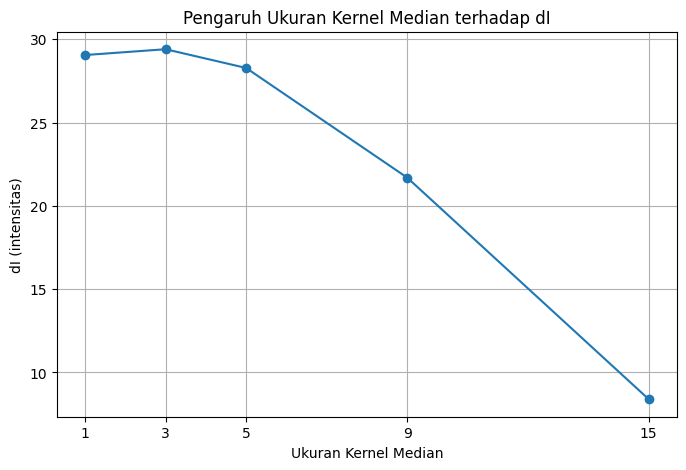

In [26]:
rata_median = (
    hasil_median.groupby("kernel")[["dI", "KB"]]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    rata_median.index,
    rata_median["dI"],
    marker="o"
)

plt.xlabel("Ukuran Kernel Median")
plt.ylabel("dI (intensitas)")
plt.title("Pengaruh Ukuran Kernel Median terhadap dI")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True)

plt.savefig("../hasil/b4_grafik_dI_median.png", dpi=150)
plt.show()

##**Memperbesar satu bercak (crop)**

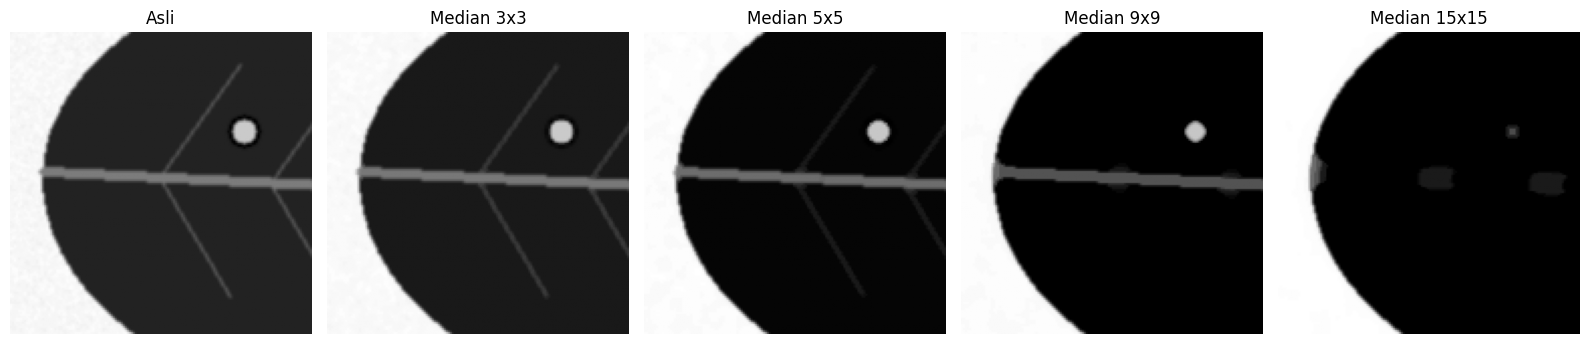

In [27]:
nama = "teh_021.png"

g = cv2.cvtColor(
    baca(f"../data/sintetis/bersih/{nama}"),
    cv2.COLOR_BGR2GRAY
)

# Koordinat crop, sesuaikan jika bercak tidak terlihat
y1, y2 = 150, 300
x1, x2 = 150, 300

crop_asli = g[y1:y2, x1:x2]

hasil_crop = [
    crop_asli,
    cv2.medianBlur(g, 3)[y1:y2, x1:x2],
    cv2.medianBlur(g, 5)[y1:y2, x1:x2],
    cv2.medianBlur(g, 9)[y1:y2, x1:x2],
    cv2.medianBlur(g, 15)[y1:y2, x1:x2]
]

judul = [
    "Asli",
    "Median 3x3",
    "Median 5x5",
    "Median 9x9",
    "Median 15x15"
]

fig, ax = plt.subplots(1, 5, figsize=(16, 4))

for a, im, title in zip(ax, hasil_crop, judul):
    a.imshow(im, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.savefig("../hasil/b4_crop_median.png", dpi=150)
plt.show()

##**Kode 4.4 Pengaruh urutan penajaman**

In [28]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)


noisy = derau["gauss_20"]

latar = md == 0  # area latar yang seharusnya rata

for nm, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():

    A = redam(unsharp(noisy))  # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))  # redam dulu, lalu tajamkan

    print(
        f"{nm}: tajam->redam "
        f"PSNR={cv2.PSNR(bersih, A):.2f} "
        f"sigma_latar={A[latar].std():.1f} | "
        f"redam->tajam "
        f"PSNR={cv2.PSNR(bersih, B):.2f} "
        f"sigma_latar={B[latar].std():.1f}"
    )

Gaussian: tajam->redam PSNR=30.39 sigma_latar=7.9 | redam->tajam PSNR=30.19 sigma_latar=8.3
Median: tajam->redam PSNR=30.10 sigma_latar=8.1 | redam->tajam PSNR=31.06 sigma_latar=7.3


##**Menentukan 12 citra kondisi normal**

In [29]:
nama_normal = [
    f"teh_{i:03d}.png"
    for i in range(1, 61, 5)
]

print(nama_normal)

['teh_001.png', 'teh_006.png', 'teh_011.png', 'teh_016.png', 'teh_021.png', 'teh_026.png', 'teh_031.png', 'teh_036.png', 'teh_041.png', 'teh_046.png', 'teh_051.png', 'teh_056.png']


##**Hitung PSNR citra kondisi normal**

In [30]:
import pandas as pd
import cv2
import numpy as np

nama_normal = [
    f"teh_{i:03d}.png"
    for i in range(1, 61, 5)
]

# Penapis pilihan
penapis_pilihan = lambda x: cv2.medianBlur(x, 5)

baris = []

for nama in nama_normal:

    # Citra dengan derau sensor bawaan
    citra = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    # Citra bersih sebagai pembanding
    bersih_normal = cv2.cvtColor(
        baca(f"../data/sintetis/bersih/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    # Penapisan
    hasil = penapis_pilihan(citra)

    # PSNR sebelum dan sesudah penapisan
    psnr_sebelum = cv2.PSNR(bersih_normal, citra)
    psnr_sesudah = cv2.PSNR(bersih_normal, hasil)

    baris.append([
        nama,
        psnr_sebelum,
        psnr_sesudah,
        psnr_sesudah - psnr_sebelum
    ])

tabel_normal = pd.DataFrame(
    baris,
    columns=[
        "nama",
        "PSNR_sebelum",
        "PSNR_sesudah",
        "peningkatan_dB"
    ]
).round(2)

print(tabel_normal)

           nama  PSNR_sebelum  PSNR_sesudah  peningkatan_dB
0   teh_001.png         30.36         40.72           10.36
1   teh_006.png         34.05         43.17            9.12
2   teh_011.png         29.78         40.18           10.40
3   teh_016.png         29.78         40.10           10.31
4   teh_021.png         29.36         39.93           10.57
5   teh_026.png         34.62         43.36            8.74
6   teh_031.png         32.53         42.02            9.49
7   teh_036.png         31.91         41.58            9.67
8   teh_041.png         29.41         39.16            9.75
9   teh_046.png         30.17         39.86            9.70
10  teh_051.png         29.43         39.29            9.86
11  teh_056.png         35.48         42.21            6.73
